In [6]:
import pandas as pd
import re

CONDITION_SYNONYMS = {
    'Atelectasis': ['atelectasis', 'atelectatic'],
    'Cardiomegaly': ['cardiomegaly', 'enlarged heart', 'cardiac enlargement'],
    'Consolidation': ['consolidation', 'consolidative', 'airspace consolidation', 'pulmonary consolidation'],
    'Edema': ['edema', 'pulmonary edema', 'fluid overload', 'pulmonary congestion'],
    'Enlarged Cardiomediastinum': ['widened mediastinum', 'mediastinal widening', 'cardiac silhouette enlargement'],
    'Fracture': ['fracture', 'rib fracture'],
    'Lung Lesion': ['lung lesion', 'pulmonary lesion', 'lung mass', 'nodule', 'pulmonary nodule'],
    'Lung Opacity': ['lung opacity', 'opacity', 'opacities', 'pulmonary opacity', 'infiltrate', 'infiltrates', 'hazy opacity'],
    'No Finding': ['no acute', 'normal', 'unremarkable'],
    'Pleural Effusion': ['pleural effusion', 'effusion', 'pleural fluid', 'pleural effusions', 'large pleural effusions', 'large pleural effusion'],
    'Pleural Other': ['pleural abnormality', 'pleural thickening'],
    'Pneumonia': [' pneumonia', 'pneumonic', 'pneumonitis'],
    'Pneumothorax': ['pneumothorax', 'pneumo', 'pneumothoraces'],
    'Support Devices': ['support devices', 'catheter', 'tube', 'ventilator', 'line', 'drain', 'device']
}

# Initialize counts
condition_counts = {condition: 0 for condition in CONDITION_SYNONYMS.keys()}

# Negation phrases
negation_phrases = ['no ', 'not ', 'without ', 'absence of ', 'negative for ', 'free of ', 'clear of ']

# Load data
df = pd.read_csv('crosstrain.csv')

# Process each report
for _, row in df.iterrows():
    report_path = row['report_path']
    try:
        with open(report_path, 'r', encoding='utf-8') as f:
            report_text = f.read()
        
        # Convert to lowercase once
        report_lower = report_text.lower()
        
        # Check each condition and its synonyms
        for condition, synonyms in CONDITION_SYNONYMS.items():
            # For "No Finding," using special logic
            if condition == 'No Finding':
                if any(synonym in report_lower for synonym in synonyms):
                    condition_counts[condition] += 1
                continue
            
            # Check if any synonym is present and not negated
            for synonym in synonyms:
                if synonym in report_lower:
                    is_negated = any(f"{negation}{synonym}" in report_lower for negation in negation_phrases)
                    if not is_negated:
                        condition_counts[condition] += 1
                        break  # Count the report once per condition
    except Exception as e:
        print(f"Error processing {report_path}: {e}")

# Print results
for condition, count in condition_counts.items():
    print(f"{condition}: {count} positive samples")

Atelectasis: 1661 positive samples
Cardiomegaly: 962 positive samples
Consolidation: 2394 positive samples
Edema: 1974 positive samples
Enlarged Cardiomediastinum: 51 positive samples
Fracture: 406 positive samples
Lung Lesion: 186 positive samples
Lung Opacity: 2118 positive samples
No Finding: 4116 positive samples
Pleural Effusion: 5272 positive samples
Pleural Other: 103 positive samples
Pneumonia: 2320 positive samples
Pneumothorax: 4090 positive samples
Support Devices: 1670 positive samples


Advanced Regex to handle negation

In [7]:
import pandas as pd
import re

CONDITION_SYNONYMS = {
    'Atelectasis': ['atelectasis', 'atelectatic'],
    'Cardiomegaly': ['cardiomegaly', 'enlarged heart', 'cardiac enlargement'],
    'Consolidation': ['consolidation', 'consolidative', 'airspace consolidation', 'pulmonary consolidation'],
    'Edema': ['edema', 'pulmonary edema', 'fluid overload', 'pulmonary congestion'],
    'Enlarged Cardiomediastinum': ['widened mediastinum', 'mediastinal widening', 'cardiac silhouette enlargement'],
    'Fracture': ['fracture', 'rib fracture'],
    'Lung Lesion': ['lung lesion', 'pulmonary lesion', 'lung mass', 'nodule', 'pulmonary nodule'],
    'Lung Opacity': ['lung opacity', 'opacity', 'opacities', 'pulmonary opacity', 'infiltrate', 'infiltrates', 'hazy opacity'],
    'No Finding': ['no acute', 'normal', 'unremarkable'],
    'Pleural Effusion': ['pleural effusion', 'effusion', 'pleural fluid', 'pleural effusions', 'large pleural effusions', 'large pleural effusion'],
    'Pleural Other': ['pleural abnormality', 'pleural thickening'],
    'Pneumonia': [' pneumonia', 'pneumonic', 'pneumonitis'],
    'Pneumothorax': ['pneumothorax', 'pneumo', 'pneumothoraces'],
    'Support Devices': ['support devices', 'catheter', 'tube', 'ventilator', 'line', 'drain', 'device']
}

# Initialize counts
condition_counts = {condition: 0 for condition in CONDITION_SYNONYMS.keys()}

# Negation phrases
negation_phrases = ['no', 'not', 'without', 'absence of', 'negative for', 'free of', 'clear of', 'declined', 'denies']

# Load data
df = pd.read_csv('crosstrain.csv')

# --- Core Logic ---
def check_for_condition(report_text, condition, synonyms, negation_phrases):
    """Checks for a condition in the report text, considering negations."""
    report_lower = report_text.lower()
    count = 0

    for synonym in synonyms:
        # Robust regex pattern
        pattern = r"(?<!\w)" + re.escape(synonym) + r"(?!\w)" # Whole word matching
        matches = list(re.finditer(pattern, report_lower))

        if matches:
            for match in matches:
                # Extract a window around the matched synonym
                start = max(0, match.start() - 50)  # 50 chars before
                end = min(len(report_lower), match.end() + 50) # 50 chars after
                window = report_lower[start:end]

                # Check for negations within the window
                is_negated = False
                for neg in negation_phrases:
                    # Negation regex (lookbehind and lookahead to prevent partial word matches)
                    neg_pattern = r"(?<!\w)" + re.escape(neg) + r"(?!\w)"  # Whole word
                    
                    # Check for negation BEFORE the synonym
                    if re.search(neg_pattern + r".{0,20}" + re.escape(synonym), window):
                        is_negated = True
                        break  # No need to check other negations if one is found

                    # Check for negation AFTER the synonym
                    if re.search(re.escape(synonym) + r".{0,10}"+ neg_pattern, window):
                        is_negated=True;
                        break;


                # Handle the "no <something> condition" case using regex.  Crucially, this is *inside*
                # the synonym loop and *inside* the match loop.  We're checking for a specific negation
                # *near* this specific instance of the synonym.
                no_something_condition_pattern = r"no\s+(?:(?!findings?|there)\w+\s+)*" + re.escape(synonym)
                if re.search(no_something_condition_pattern, window):
                    is_negated = True

                if not is_negated:
                    count = 1  # We found at least one non-negated instance.
                    return count  # Stop after finding one positive mention

    return count

# Process each report
for _, row in df.iterrows():
    report_path = row['report_path']
    try:
        with open(report_path, 'r', encoding='utf-8') as f:
            report_text = f.read()

        for condition, synonyms in CONDITION_SYNONYMS.items():
            if condition == 'No Finding':
                # Special handling for "No Finding" (Simplified with regex)
                if any(re.search(r"(?<!\w)" + re.escape(syn) + r"(?!\w)", report_text.lower()) for syn in synonyms):
                    condition_counts[condition] += 1
            else:
                # Use the improved function
                condition_counts[condition] += check_for_condition(report_text, condition, synonyms, negation_phrases)

    except Exception as e:
        print(f"Error processing {report_path}: {e}")

# Print results
for condition, count in condition_counts.items():
    print(f"{condition}: {count} positive samples")

Atelectasis: 1558 positive samples
Cardiomegaly: 878 positive samples
Consolidation: 726 positive samples
Edema: 1359 positive samples
Enlarged Cardiomediastinum: 45 positive samples
Fracture: 164 positive samples
Lung Lesion: 103 positive samples
Lung Opacity: 1999 positive samples
No Finding: 3997 positive samples
Pleural Effusion: 2715 positive samples
Pleural Other: 89 positive samples
Pneumonia: 464 positive samples
Pneumothorax: 1273 positive samples
Support Devices: 1170 positive samples


Used NegSpacy

In [16]:
import pandas as pd
import re
import spacy
from spacy.tokens import Span

# Load spaCy model
nlp = spacy.load("en_core_web_sm")

# Add Negex component with custom entity type
nlp.add_pipe("negex", config={"ent_types": ["CONDITION"]})

CONDITION_SYNONYMS = {
    'Atelectasis': ['atelectasis', 'atelectatic'],
    'Cardiomegaly': ['cardiomegaly', 'enlarged heart', 'cardiac enlargement'],
    'Consolidation': ['consolidation', 'consolidative', 'airspace consolidation', 'pulmonary consolidation'],
    'Edema': ['edema', 'pulmonary edema', 'fluid overload', 'pulmonary congestion'],
    'Enlarged Cardiomediastinum': ['widened mediastinum', 'mediastinal widening', 'cardiac silhouette enlargement'],
    'Fracture': ['fracture', 'rib fracture'],
    'Lung Lesion': ['lung lesion', 'pulmonary lesion', 'lung mass', 'nodule', 'pulmonary nodule'],
    'Lung Opacity': ['lung opacity', 'opacity', 'opacities', 'pulmonary opacity', 'infiltrate', 'infiltrates', 'hazy opacity'],
    'No Finding': ['no acute', 'normal', 'unremarkable'],
    'Pleural Effusion': ['pleural effusion', 'effusion', 'pleural fluid', 'pleural effusions', 'large pleural effusions', 'large pleural effusion'],
    'Pleural Other': ['pleural abnormality', 'pleural thickening'],
    'Pneumonia': [' pneumonia', 'pneumonic', 'pneumonitis'],
    'Pneumothorax': ['pneumothorax', 'pneumo', 'pneumothoraces'],
    'Support Devices': ['support devices', 'catheter', 'tube', 'ventilator', 'line', 'drain', 'device']
}

# Initialize counts
condition_counts = {condition: 0 for condition in CONDITION_SYNONYMS.keys()}

# Load data
df = pd.read_csv('crosstrain.csv')

# --- Core Logic ---
def check_for_condition(doc, synonyms):
    """Check if any synonym in the doc is non-negated."""
    spans = []
    for synonym in synonyms:
        pattern = r"(?<!\w)" + re.escape(synonym) + r"(?!\w)"
        for match in re.finditer(pattern, doc.text):
            start_char, end_char = match.start(), match.end()
            start_token = end_token = None
            for token in doc:
                if token.idx >= start_char and start_token is None:
                    start_token = token.i
                if token.idx + len(token.text) > end_char and end_token is None:
                    end_token = token.i + 1
            if start_token is not None and end_token is not None:
                spans.append((Span(doc, start_token, end_token, label="CONDITION"), start_char, end_char))

    # Sort spans by length (shorter first) and deduplicate by position
    spans.sort(key=lambda x: (x[2] - x[1], x[1]))  # Sort by length, then start position
    unique_spans = []
    used_tokens = set()
    for span, start, end in spans:
        span_tokens = set(range(span.start, span.end))
        if not span_tokens & used_tokens:  # No overlap with previously used tokens
            unique_spans.append(span)
            used_tokens.update(span_tokens)

    # Set entities and process with pipeline
    doc.ents = unique_spans
    doc = nlp(doc)

    # Check for non-negated entities
    for ent in doc.ents:
        if ent.label_ == "CONDITION" and not ent._.negex:
            return 1  # Found a non-negated mention
    return 0

# Process each report
for _, row in df.iterrows():
    report_path = row['report_path']
    try:
        with open(report_path, 'r', encoding='utf-8') as f:
            report_text = f.read()

        # Create a doc without processing the pipeline yet
        doc = nlp.make_doc(report_text.lower())  # Lowercase for consistency

        # Process "No Finding" separately
        if any(re.search(r"(?<!\w)" + re.escape(syn) + r"(?!\w)", doc.text) for syn in CONDITION_SYNONYMS['No Finding']):
            condition_counts['No Finding'] += 1

        # Process other conditions
        for condition, synonyms in CONDITION_SYNONYMS.items():
            if condition != 'No Finding':
                # Create a fresh doc for each condition to avoid entity conflicts
                temp_doc = nlp.make_doc(report_text.lower())
                if check_for_condition(temp_doc, synonyms):
                    condition_counts[condition] += 1

    except Exception as e:
        print(f"Error processing {report_path}: {e}")

# Print results
for condition, count in condition_counts.items():
    print(f"{condition}: {count} positive samples")

Atelectasis: 1621 positive samples
Cardiomegaly: 911 positive samples
Consolidation: 575 positive samples
Edema: 1066 positive samples
Enlarged Cardiomediastinum: 35 positive samples
Fracture: 142 positive samples
Lung Lesion: 100 positive samples
Lung Opacity: 1906 positive samples
No Finding: 3997 positive samples
Pleural Effusion: 1697 positive samples
Pleural Other: 83 positive samples
Pneumonia: 377 positive samples
Pneumothorax: 267 positive samples
Support Devices: 1161 positive samples


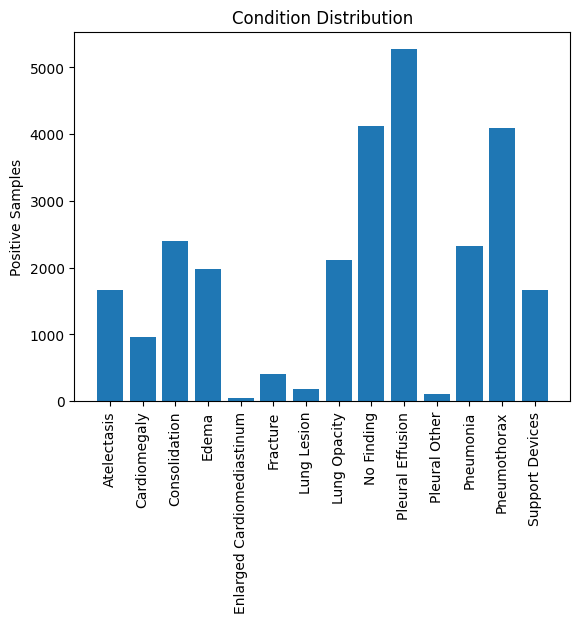

In [7]:
import matplotlib.pyplot as plt
plt.bar(condition_counts.keys(), condition_counts.values())
plt.xticks(rotation=90)
plt.ylabel("Positive Samples")
plt.title("Condition Distribution")
plt.show()